# CoSTA for a simulated wind turbine with synthetic blade erosion

**All data in this notebook are synthetic.** The "logs" come from a simulated NREL-5MW-like turbine whose power
coefficient we degrade with a prescribed erosion law. No measured turbine data are used. That lets us check every
step against the known truth, which a real data set would not allow.

The **physics-based model (PBM)** is the single-mass drivetrain with the design power coefficient $C_p$,

$$J\dot\omega=T_{\text{aero}}^{\text{nom}}(\omega,v,\beta)-T_{\text{gen}},$$

where $\omega$ is the rotor speed, $v$ the wind speed and $\beta$ the blade pitch. The **reference** turbine has
eroded blades, so its aerodynamic torque is lower, and the PBM over-predicts power. CoSTA keeps the PBM, its
integrator and its controller, and adds a learned torque correction inside each step:

$$J\,\frac{\omega_{k+1}-\omega_k}{\Delta t}=T_{\text{aero}}^{\text{nom}}(\omega_k,v_k,\beta_k)-T_{\text{gen},k}
+\sigma_{\boldsymbol{\theta}}(\omega_k,v_k,\beta_k).$$

The protocol is the one from the heat notebook:

1. **Partition** independent wind realizations into training, validation and test cases *before* building any sample.
2. **Build labels** from synchronized logged samples and the PBM: the torque the PBM is missing at each step.
3. **Train** the correction by supervised regression on the training cases only.
4. **Validate**: at fixed checkpoints run recursive simulations of the validation cases and keep the best checkpoint.
5. **Test**: freeze the selected model and run recursive simulations on held-out wind, in the training regime and
   in a different one. The reference is used only to score.

The prose narrates the **default** run. Change the values below and *Run All*; every figure, table and saved
result follows. Checks that quote the default numbers are skipped when the parameters differ from the defaults.

In [1]:
# ---- Parameters (edit these, then Run All) -------------------------------
SEED = 0                       # network initialization seed for the walkthrough
N_SAMPLES, DT = 2500, 0.1      # samples per wind realization and time step [s] (250 s per case)
TI, TAU = 0.08, 25.0           # turbulence intensity and correlation time [s] of the OU wind
EROSION = 0.015                # synthetic erosion law: Cp_true = Cp_nom (1 - EROSION * lambda)
# wind realizations: (mean wind [m/s], forcing seed), one complete series per case, fixed before tuning
CASES_TRAIN = [(9.0, 1), (9.0, 2), (9.0, 3)]
CASES_VAL = [(9.0, 11), (9.0, 12)]               # checkpoint selection only
CASES_TEST_SAME = [(9.0, 21), (9.0, 22)]         # held out, same mean wind as training
CASES_TEST_TRANSFER = [(11.5, 31), (11.5, 32)]   # held out, around rated wind: pitch active
CASES_HISTORICAL = [(11.5, 5)]                   # plotted in earlier versions: diagnostic only
CASES_AUG = [(12.0, 41), (12.0, 42)]             # coverage ablation: extra above-rated training cases
SHOW_CASE = (9.0, 21)                            # same-regime test case drawn in the time-series figure
SHOW_TRANSFER = (11.5, 31)                       # transfer test case drawn in the transfer figure
OMEGA_NOISE = 0.0              # std of rotor-speed measurement noise in the logs [rad/s]; 0 = clean logs
NOISE_SEED = 1000              # measurement-noise seed (separate from wind and network seeds)
INPUT_STD_FLOOR = [0.02, 0.5, 1.0]  # lower bounds on the input scales: omega [rad/s], v [m/s], beta [deg]
HIDDEN = [32, 32]
LR, MAX_STEPS = 3e-3, 3000     # Adam, full batch; learning rate halves every LR_HALVE steps
LR_HALVE = 1000
VAL_EVERY = 250                # validation interval [steps]
PATIENCE = 6                   # stop after this many validations without improvement
MIN_REL_IMPROVEMENT = 0.01     # an improvement must beat the best by 1 %
ALPHAS = [0.0, 0.25, 0.5, 0.75, 1.0]   # correction scales for the alpha check on SHOW_CASE
RUN_COVERAGE_ABLATION = True   # retrain with CASES_AUG added to the training set
RUN_PITCH_ABLATION = True      # also retrain on the augmented set without the pitch input
RUN_SEED_SWEEP = True          # retrain all variants for SWEEP_SEEDS (~1.5 min idle); False loads the saved table
SWEEP_SEEDS = [0, 1, 2, 3, 4]
# --------------------------------------------------------------------------

DEFAULTS = dict(SEED=0, N_SAMPLES=2500, DT=0.1, TI=0.08, TAU=25.0, EROSION=0.015,
                CASES_TRAIN=[(9.0, 1), (9.0, 2), (9.0, 3)], CASES_VAL=[(9.0, 11), (9.0, 12)],
                CASES_TEST_SAME=[(9.0, 21), (9.0, 22)], CASES_TEST_TRANSFER=[(11.5, 31), (11.5, 32)],
                CASES_AUG=[(12.0, 41), (12.0, 42)], OMEGA_NOISE=0.0, INPUT_STD_FLOOR=[0.02, 0.5, 1.0],
                HIDDEN=[32, 32], LR=3e-3, MAX_STEPS=3000, LR_HALVE=1000, VAL_EVERY=250, PATIENCE=6,
                MIN_REL_IMPROVEMENT=0.01)
AT_DEFAULTS = all(globals()[k] == v for k, v in DEFAULTS.items())

### Setup: the turbine, its controller, and the synthetic erosion

Constants and the Heier power-coefficient map come from the course benchmark `pyutils.benchmarks.turbine`
(`TurbineParams`): $\rho=1.225$ kg/m³, $R=63$ m, $J=3.86\times10^7$ kg·m², rated power 5 MW, $C_{p,\max}\approx0.48$
at $\lambda_{\text{opt}}\approx8.1$, where $\lambda=\omega R/v$ is the tip-speed ratio. The controller is the
benchmark's: below rated, $\beta=0$ and $T_{\text{gen}}=K\omega^2$; above rated, the torque saturates at
$T_{\text{rated}}$ and a PI loop pitches the blades to hold $\omega_{\text{rated}}$.

The **synthetic degradation** is a tip-erosion law that removes the fraction $0.015\,\lambda$ of the power coefficient,

$$T_{\text{aero}}^{\text{true}}=T_{\text{aero}}^{\text{nom}}\,(1-0.015\,\lambda),\qquad
\delta(\omega,v,\beta)=T_{\text{aero}}^{\text{true}}-T_{\text{aero}}^{\text{nom}}<0 .$$

About 12 % of the torque is lost at $\lambda_{\text{opt}}$. The torque deficit $\delta$ is the missing physics. Only the
reference simulator uses the erosion law; the PBM and CoSTA never see it. We use $\delta$ itself only as an
independent diagnostic.

In [2]:
import sys, os, copy, json, time
sys.path.insert(0, os.path.abspath(os.path.join('..', '..')))  # -> python/
import numpy as np, torch, matplotlib.pyplot as plt
from pyutils import pinn_core as pc
from pyutils.pinn_core import MLP
from pyutils import save_dual, fg, muted
from pyutils.benchmarks.turbine import TurbineParams
torch.set_default_dtype(torch.float64)
pc.set_plot_style()
FIG = os.path.abspath(os.path.join('..', 'figures')); os.makedirs(FIG, exist_ok=True)
DATA = os.path.abspath(os.path.join('..', 'data')); os.makedirs(DATA, exist_ok=True)
RESULTS_FILE = os.path.join(DATA, 'costa_turbine_results.json')
T_START = time.time()

TP = TurbineParams()
RHO, R_ROT, A_ROT, J = TP.rho, TP.R, TP.A, TP.J
K_GEN, T_RATED, OMEGA_RATED, V_RATED = TP.K, TP.T_rated, TP.omega_rated, TP.v_rated
RPM = 30/np.pi                                     # rad/s -> rpm

def T_nom(omega, v, beta):
    """PBM aerodynamic torque [N m] with the design Cp (vectorized)."""
    return 0.5*RHO*A_ROT*TP.Cp(omega*R_ROT/v, beta)*v**3/np.maximum(omega, 0.1)

def T_true(omega, v, beta):
    """Reference (eroded) aerodynamic torque. Used only to generate the synthetic logs."""
    lam = omega*R_ROT/v
    return T_nom(omega, v, beta)*(1 - EROSION*np.maximum(lam, 0.0))

def deficit(omega, v, beta):
    """Oracle torque deficit delta = T_true - T_nom: a diagnostic, never a training label."""
    return T_true(omega, v, beta) - T_nom(omega, v, beta)

# The benchmark's simulate() has no hook for the aerodynamic torque, which CoSTA must modify, so this notebook
# keeps a local version of the same closed loop (explicit Euler drivetrain, generator-torque law, pitch PI with
# anti-windup).
def simulate(v_arr, aero):
    """Closed-loop simulation; aero(omega, v, beta) returns the aerodynamic torque used in the model.

    Every logged quantity is stored at the same step index k, *before* the update:
    omega_k, v_k, beta_k, T_gen_k, and the power P_k = T_gen_k * omega_k. omega has one extra entry, omega_n.
    The model sees only the prescribed wind and its own state; nothing from a reference run.
    """
    n = len(v_arr)
    OM = np.empty(n + 1); BE = np.empty(n); TG = np.empty(n)
    omega = min(TP.lam_opt*v_arr[0]/R_ROT, OMEGA_RATED); beta = 0.0; integ = 0.0; clamped = 0
    for k in range(n):
        v = v_arr[k]
        OM[k], BE[k] = omega, beta
        Ta = aero(omega, v, beta)
        Tg = min(K_GEN*omega**2, T_RATED); TG[k] = Tg
        err = omega - OMEGA_RATED; integ += err*DT                 # pitch PI -> beta_{k+1}
        bc = TP.Kp*err + TP.Ki*integ; beta = min(max(bc, 0.0), TP.beta_max)
        if beta != bc:                                             # anti-windup
            integ = (beta - TP.Kp*err)/TP.Ki
        omega = omega + DT*(Ta - Tg)/J                             # explicit Euler drivetrain
        if not np.isfinite(omega):
            OM[k+1:] = np.nan; BE[k+1:] = np.nan; TG[k+1:] = np.nan; break
        if omega < 0.1:
            omega = 0.1; clamped += 1
    OM[n] = omega
    return dict(omega=OM, v=np.asarray(v_arr), beta=BE, T_gen=TG, P=TG*OM[:-1], clamped=clamped)

print(f'lambda_opt = {TP.lam_opt:.2f}, Cp_max = {TP.Cp_max:.3f}, v_rated = {V_RATED:.2f} m/s, '
      f'omega_rated = {OMEGA_RATED:.3f} rad/s ({OMEGA_RATED*RPM:.1f} rpm), T_rated = {T_RATED/1e6:.2f} MN m')
print(f'torque lost at lambda_opt: {100*EROSION*TP.lam_opt:.1f} %')

lambda_opt = 8.10, Cp_max = 0.480, v_rated = 11.09 m/s, omega_rated = 1.426 rad/s (13.6 rpm), T_rated = 3.51 MN m
torque lost at lambda_opt: 12.2 %


## 1. Wind realizations, partitioned first

A **case** is one complete 250 s wind realization: an Ornstein–Uhlenbeck series (turbulence intensity 0.08,
correlation time 25 s) around a mean wind, identified by (mean, forcing seed). Cases are assigned to roles before
any sample is extracted, so every time step of a realization stays in that realization's role.

| Role | Cases | Purpose |
|---|---|---|
| training | 9 m/s, seeds 1, 2, 3 | fit the weights and the normalization |
| validation | 9 m/s, seeds 11, 12 | choose the checkpoint |
| test, same regime | 9 m/s, seeds 21, 22 | final score in the training regime |
| test, transfer | 11.5 m/s, seeds 31, 32 | final score around rated wind, where the pitch controller is active |
| historical | 11.5 m/s, seed 5 | the transfer case plotted in earlier versions; a diagnostic only |
| coverage ablation | 12 m/s, seeds 41, 42 | extra training cases for Section 7 only |

Rated wind is about 11.1 m/s. Below it the pitch stays at zero; above it the controller pitches the blades. So the
11.5 m/s cases are not just "a different wind": the turbine works in a different control regime there.

In [3]:
def wind(v_mean, seed, n=N_SAMPLES):
    """OU turbulence around v_mean (the series used in earlier versions of this notebook)."""
    rng = np.random.default_rng(seed); u = 0.0; out = []
    for _ in range(n):
        u += DT*(-u/TAU) + TI*v_mean*np.sqrt(2*DT/TAU)*rng.standard_normal(); out.append(v_mean + u)
    return np.clip(np.array(out), 3.0, 25.0)

SPLIT = {'train': CASES_TRAIN, 'val': CASES_VAL, 'test_same': CASES_TEST_SAME,
         'test_transfer': CASES_TEST_TRANSFER, 'historical': CASES_HISTORICAL, 'aug': CASES_AUG}
roles = list(SPLIT)
for i, ri in enumerate(roles):
    for rj in roles[i+1:]:
        assert not set(SPLIT[ri]) & set(SPLIT[rj]), f'{ri} and {rj} share cases'
all_seeds = [s for cs in SPLIT.values() for _, s in cs]
assert len(all_seeds) == len(set(all_seeds)), 'every wind realization needs its own forcing seed'
ROLE_LABEL = {'train': 'training', 'val': 'validation', 'test_same': 'test, same regime',
              'test_transfer': 'test, transfer', 'historical': 'historical diagnostic', 'aug': 'ablation training'}
ROLE_COLOR = {'train': 'C0', 'val': 'C4', 'test_same': 'C2', 'test_transfer': 'C3', 'historical': None, 'aug': 'C1'}
CASE_ROLE = {c: role for role, cs in SPLIT.items() for c in cs}
MANIFEST = {role: [dict(case=f'{role}-{k}', v_mean=vm, wind_seed=s, TI=TI, tau=TAU, n_samples=N_SAMPLES, dt=DT,
                        omega0='min(lambda_opt v_0 / R, omega_rated)', beta0=0.0, integrator='explicit Euler')
                   for k, (vm, s) in enumerate(cs)] for role, cs in SPLIT.items()}

# synthetic "logs": the reference turbine run under each wind realization
WIND = {c: wind(*c) for c in CASE_ROLE}
REF = {c: simulate(WIND[c], T_true) for c in CASE_ROLE}
assert all(REF[c]['clamped'] == 0 and np.all(np.isfinite(REF[c]['omega'])) for c in REF)

Before training anything, look at where each case puts the turbine. For every case the table lists the wind range,
the fraction of steps with the pitch active ($\beta>0$), and the fraction of logged states $(\omega,v,\beta)$
outside the **training box**, the smallest box containing all training states. A state outside the box asks the
network to extrapolate in at least one input.

In [4]:
def box(cases):
    S = np.vstack([np.column_stack([REF[c]['omega'][:-1], REF[c]['v'], REF[c]['beta']]) for c in cases])
    return S.min(0), S.max(0)

def outside(c, bx):
    S = np.column_stack([REF[c]['omega'][:-1], REF[c]['v'], REF[c]['beta']])
    return float(np.mean(np.any((S < bx[0] - 1e-12) | (S > bx[1] + 1e-12), axis=1)))

BOX = {'train': box(CASES_TRAIN), 'train+aug': box(CASES_TRAIN + CASES_AUG)}
REGIME = {}
print(f"{'role':22s} {'case':>11s} | {'wind [m/s]':>11s} {'beta>0':>7s} {'max beta':>8s} | "
      f"{'outside box: train':>18s} {'train+aug':>9s}")
for c, role in CASE_ROLE.items():
    L = REF[c]
    REGIME[c] = dict(v_min=float(L['v'].min()), v_max=float(L['v'].max()),
                     frac_pitch=float(np.mean(L['beta'] > 0)), beta_max=float(L['beta'].max()),
                     frac_out_train=outside(c, BOX['train']), frac_out_aug=outside(c, BOX['train+aug']))
    g = REGIME[c]
    print(f"{ROLE_LABEL[role]:22s} {c[0]:5.1f}/{c[1]:<5d} | {g['v_min']:4.1f}-{g['v_max']:4.1f}   "
          f"{100*g['frac_pitch']:6.1f}% {g['beta_max']:7.2f}° | {100*g['frac_out_train']:17.1f}% "
          f"{100*g['frac_out_aug']:8.1f}%")
print('training box: omega [%.3f, %.3f] rad/s, v [%.2f, %.2f] m/s, beta [%.2f, %.2f] deg'
      % (BOX['train'][0][0], BOX['train'][1][0], BOX['train'][0][1], BOX['train'][1][1],
         BOX['train'][0][2], BOX['train'][1][2]))

role                          case |  wind [m/s]  beta>0 max beta | outside box: train train+aug
training                 9.0/1     |  7.1-10.6      0.0%    0.00° |               0.0%      0.0%
training                 9.0/2     |  7.0- 9.6      0.0%    0.00° |               0.0%      0.0%
training                 9.0/3     |  8.1-10.9      0.0%    0.00° |               0.0%      0.0%
validation               9.0/11    |  7.8-10.2      0.0%    0.00° |               0.0%      0.0%
validation               9.0/12    |  8.4-10.4      0.0%    0.00° |               0.0%      0.0%
test, same regime        9.0/21    |  7.5-11.9      1.2%    0.06° |              28.4%      0.0%
test, same regime        9.0/22    |  7.6-10.4      0.0%    0.00° |               0.0%      0.0%
test, transfer          11.5/31    |  9.6-13.8     39.8%    4.81° |              99.4%      6.4%
test, transfer          11.5/32    |  9.3-13.8     42.1%    4.16° |              83.1%      2.6%
historical diagnostic   11.5/5

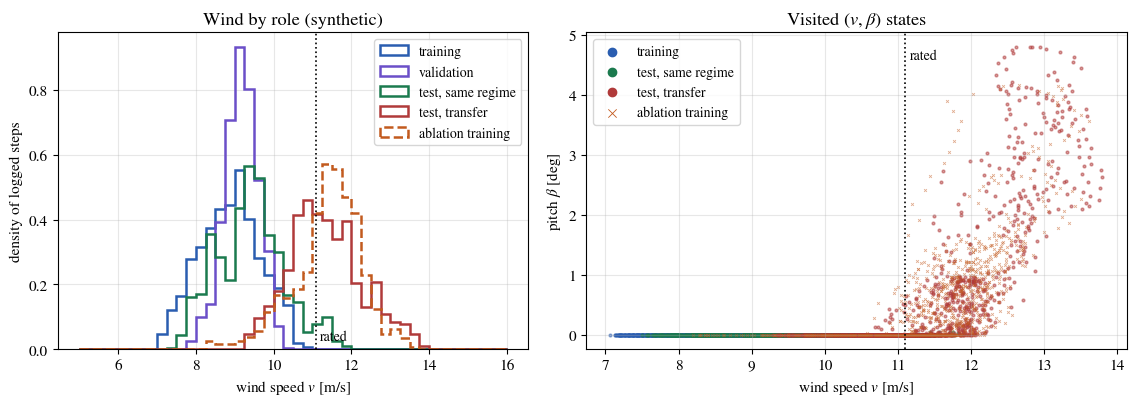

In [5]:
def plot_wind_costa_split():
    fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.2), gridspec_kw=dict(width_ratios=[1, 1.15]))
    bins = np.linspace(5, 16, 45)
    for role in ['train', 'val', 'test_same', 'test_transfer', 'aug']:
        v = np.concatenate([REF[c]['v'] for c in SPLIT[role]])
        ax[0].hist(v, bins=bins, density=True, histtype='step', lw=1.8, color=ROLE_COLOR[role],
                   ls='--' if role == 'aug' else '-', label=ROLE_LABEL[role])
    ax[0].axvline(V_RATED, color=fg(), ls=':', lw=1.2)
    ax[0].text(V_RATED + 0.1, ax[0].get_ylim()[1]*0.03, 'rated', fontsize=10)
    ax[0].set(xlabel='wind speed $v$ [m/s]', ylabel='density of logged steps', title='Wind by role (synthetic)')
    ax[0].legend(fontsize=10, loc='upper right')
    for role in ['train', 'test_same', 'test_transfer', 'aug']:
        S = np.vstack([np.column_stack([REF[c]['v'], REF[c]['beta']]) for c in SPLIT[role]])
        ax[1].scatter(S[::4, 0], S[::4, 1], s=4, alpha=0.5, color=ROLE_COLOR[role], label=ROLE_LABEL[role],
                      marker='x' if role == 'aug' else 'o', lw=0.6 if role == 'aug' else None)
    ax[1].axvline(V_RATED, color=fg(), ls=':', lw=1.2)
    ax[1].set(xlabel='wind speed $v$ [m/s]', ylabel=r'pitch $\beta$ [deg]', title='Visited $(v,\\beta)$ states')
    ax[1].text(V_RATED + 0.08, 4.6 if REF[CASES_TEST_TRANSFER[0]]['beta'].max() > 4.6 else 0.9*ax[1].get_ylim()[1],
               'rated', fontsize=10)
    leg = ax[1].legend(fontsize=10, markerscale=3, loc='upper left')
    for h in leg.legend_handles:
        h.set_alpha(1)
    plt.tight_layout()

save_dual(plot_wind_costa_split, 'wind_costa_split', FIG)
plt.show()

The three training realizations span 7.0–10.9 m/s and never pitch, so the training box has $\beta\in[0,0]$: every
training state lies on the below-rated operating curve, where the controller holds $\lambda$ near $\lambda_{\text{opt}}$.
The validation cases stay inside that box.

The table already shows that "same mean wind" does not guarantee "same states". Test case 9/22 stays inside the
training box, but 9/21 has a gust to 11.9 m/s: 28 % of its states lie outside the box and the pitch briefly
activates (1.2 % of the steps). The transfer cases at 11.5 m/s pitch in about 40 % of the steps, up to 4.8°, and
83–99 % of their states are outside the training box. The historical seed-5 case pitches in 74 % of the steps and
lies entirely outside it. Adding the two 12 m/s ablation realizations to the training set shrinks the out-of-box
fraction of the transfer cases to 3–6 %.

In the right panel the training and same-regime states sit on the line $\beta=0$; only the transfer and ablation
cases leave it. A network that has only seen $\beta=0$ has no data about how the correction depends on pitch.

## 2. Labels from the logs: the torque the PBM is missing

A turbine log contains synchronized samples of rotor speed, wind, pitch and generator torque. From two consecutive
samples and the PBM we can compute the torque the PBM's step would have needed to land on the logged next speed:

$$\sigma^*_k=J\,\frac{\omega_{k+1}-\omega_k}{\Delta t}+T_{\text{gen},k}-T_{\text{aero}}^{\text{nom}}(\omega_k,v_k,\beta_k).$$

This is the exact discrete correction for the PBM's explicit-Euler step, the turbine counterpart of the heat
notebook's label. The time levels matter:

* the **features** $(\omega_k,v_k,\beta_k)$ are all taken at step $k$; the generator torque in the label is $T_{\text{gen},k}$, from the
  same step;
* the **label** needs $\omega_{k+1}$, which is available when building the training set but **not** when predicting.

Earlier versions of this notebook stored the post-step speed next to the pre-step wind, and multiplied the old
generator torque by the new speed to get power. Here every quantity is logged at the same index $k$, and
$P_k=T_{\text{gen},k}\,\omega_k$.

**Why the label equals the true deficit here.** The synthetic reference advances with the same explicit-Euler step,
$\omega_{k+1}=\omega_k+\Delta t\,(T_{\text{aero}}^{\text{true}}-T_{\text{gen},k})/J$. Substituting gives
$\sigma^*_k=T_{\text{aero}}^{\text{true}}-T_{\text{aero}}^{\text{nom}}=\delta(\omega_k,v_k,\beta_k)$ up to round-off. With a real
turbine (continuous dynamics, sensor noise, a different sampling rate) $\sigma^*_k$ would also contain
discretization and noise error, so the label would no longer coincide with the physical deficit.

In [6]:
def labels_from_log(L, noise=OMEGA_NOISE, seed=NOISE_SEED):
    """Feature rows (omega_k, v_k, beta_k) and residual labels sigma*_k from one logged run."""
    om = L['omega'].copy()
    if noise > 0:
        om = om + np.random.default_rng(seed).normal(0.0, noise, om.shape)
    F = np.column_stack([om[:-1], L['v'], L['beta']])
    y = J*(om[1:] - om[:-1])/DT + L['T_gen'] - T_nom(om[:-1], L['v'], L['beta'])
    return F, y

def dataset(cases):
    F, Y = zip(*[labels_from_log(REF[c], seed=NOISE_SEED + c[1]) for c in cases])
    return np.vstack(F), np.concatenate(Y)[:, None]

# check: in the clean synthetic logs the residual label is the oracle deficit
worst = 0.0
for c in CASE_ROLE:
    F, y = labels_from_log(REF[c], noise=0.0)
    worst = max(worst, np.abs(y - deficit(F[:, 0], F[:, 1], F[:, 2])).max())
print(f'clean logs: max |sigma* - delta| = {worst:.1e} N m  (deficits are ~1e5 N m)')
assert worst < 1e-3

k0, c0 = 1000, CASES_TRAIN[0]
F0, y0 = labels_from_log(REF[c0])
print(f'sample (training case {c0}, k = {k0}, t = {k0*DT:.0f} s): features omega = {F0[k0, 0]:.4f} rad/s, '
      f'v = {F0[k0, 1]:.3f} m/s, beta = {F0[k0, 2]:.2f} deg')
print(f'  label sigma* = {y0[k0]/1e3:.1f} kN m   (oracle delta {deficit(*F0[k0])/1e3:.1f} kN m, '
      f'nominal torque {T_nom(*F0[k0])/1e3:.0f} kN m)')
print(f'label noise for a speed-noise std s: J sqrt(2) s / dt = {J*np.sqrt(2)/DT/1e3:.0f} kN m per rad/s of s')

clean logs: max |sigma* - delta| = 4.3e-08 N m  (deficits are ~1e5 N m)
sample (training case (9.0, 1), k = 1000, t = 100 s): features omega = 1.0029 rad/s, v = 8.288 m/s, beta = 0.00 deg
  label sigma* = -235.3 kN m   (oracle delta -235.3 kN m, nominal torque 2058 kN m)
label noise for a speed-noise std s: J sqrt(2) s / dt = 545886 kN m per rad/s of s


The check passes: in the clean synthetic logs, $\sigma^*_k$ and the oracle $\delta$ differ by at most
$4\times10^{-8}$ N·m, for deficits of a few hundred kN·m. The worked sample shows one row of the learning problem:
three inputs at step $k$, and a label of $-235$ kN·m, about 11 % of the nominal aerodynamic torque, that needs the
speed at step $k+1$.

**Measurement noise.** `OMEGA_NOISE` adds Gaussian noise of standard deviation $s$ to the logged rotor speed before
the labels are formed (the reference rollouts used for scoring stay clean). Differencing amplifies it: the label
noise has standard deviation $\sqrt2\,J s/\Delta t\approx 546$ kN·m per rad/s of $s$, so $s=10^{-4}$ rad/s already
gives about 55 kN·m and $s=10^{-3}$ rad/s gives more than the deficit itself. The regression then averages noisy
labels, and the assert above is skipped by design because $\sigma^*_k\neq\delta$. In practice one would filter
the speed signal or difference over a longer interval, and choose that setting on validation data. Try
$s=10^{-4}$ and $10^{-3}$ and compare the test table.

## 3. Training with validation-based checkpoint selection

The network $\sigma_{\boldsymbol{\theta}}(\omega,v,\beta)$ takes the pitch as an input, because the missing torque depends on it.
Inputs are centred on the training mean and divided by the training standard deviation, but never by less than
a declared floor (0.02 rad/s, 0.5 m/s, 1°). The floor matters: the 9 m/s training cases never pitch, so
the training standard deviation of $\beta$ is zero, and dividing by it would send any pitched state to infinity.
All statistics come from **training rows only** and are applied unchanged to validation and test inputs.

Every `VAL_EVERY` Adam steps, without updating the weights, we record

* the correction MSE on the validation logs (a regression diagnostic on reference-state inputs);
* the **mean power MAE** of recursive validation simulations: each validation wind drives the PBM plus
  $\sigma_{\boldsymbol{\theta}}$, with its own controller, from the declared initial speed; the model's own $\omega$ is fed back.

The checkpoint with the lowest validation power MAE is kept; a non-finite rollout counts as $+\infty$. Training
stops after `PATIENCE` validations without a 1 % improvement, and the selected checkpoint is restored.

In [7]:
class Correction:
    """A trained torque correction: network + training-set normalization, evaluated in NumPy for speed."""
    def __init__(self, net, stats, cols=(0, 1, 2)):
        self.net, self.stats, self.cols = net, stats, list(cols)   # cols: which of (omega, v, beta) are inputs
        self.refresh()
    def refresh(self):                               # copy the current weights into NumPy
        lin = [m for m in self.net.net if isinstance(m, torch.nn.Linear)]
        self.W = [m.weight.detach().numpy().copy() for m in lin]
        self.b = [m.bias.detach().numpy().copy() for m in lin]
    def batch(self, F):
        Fm, Fs, Ym, Ys = self.stats
        h = (np.atleast_2d(F)[:, self.cols] - Fm)/Fs
        for i, (W, b) in enumerate(zip(self.W, self.b)):
            h = h @ W.T + b
            if i < len(self.W) - 1:
                h = np.tanh(h)
        return h[:, 0]*Ys + Ym
    def __call__(self, omega, v, beta):
        return float(self.batch(np.array([omega, v, beta]))[0])

def costa_aero(corr, alpha=1.0):
    return lambda omega, v, beta: T_nom(omega, v, beta) + alpha*corr(omega, v, beta)

def power_mae_kw(Lm, Lr):
    return float(np.mean(np.abs(Lm['P'] - Lr['P'])))/1e3 if np.all(np.isfinite(Lm['P'])) else float('inf')

def normalization(F, Y, cols):
    return F.mean(0), np.maximum(F.std(0), np.array(INPUT_STD_FLOOR)[cols]), Y.mean(), Y.std()

def fit_costa(train_cases, seed=SEED, cols=(0, 1, 2), verbose=False):
    cols = list(cols)
    F, Y = dataset(train_cases); Fv, Yv = dataset(CASES_VAL); F, Fv = F[:, cols], Fv[:, cols]
    stats = normalization(F, Y, cols); Fm, Fs, Ym, Ys = stats       # training rows only
    Ft, Yt = torch.tensor((F-Fm)/Fs), torch.tensor((Y-Ym)/Ys)
    Fvt, Yvt = torch.tensor((Fv-Fm)/Fs), torch.tensor((Yv-Ym)/Ys)
    torch.manual_seed(seed)
    net = MLP([len(cols), *HIDDEN, 1]); corr = Correction(net, stats, cols)
    opt = torch.optim.Adam(net.parameters(), lr=LR)
    sched = torch.optim.lr_scheduler.StepLR(opt, step_size=LR_HALVE, gamma=0.5)
    hist = dict(step=[], train_mse=[], val_mse=[], val_power_mae=[])
    best, best_step, best_state, waited = np.inf, 0, None, 0
    for k in range(MAX_STEPS + 1):
        if k % VAL_EVERY == 0 or k == MAX_STEPS:
            corr.refresh()
            with torch.no_grad():
                tr = ((net(Ft) - Yt)**2).mean().item(); va = ((net(Fvt) - Yvt)**2).mean().item()
            vp = float(np.mean([power_mae_kw(simulate(WIND[c], costa_aero(corr)), REF[c]) for c in CASES_VAL]))
            for key, val in zip(hist, (k, tr, va, vp)):
                hist[key].append(val)
            if vp < best*(1 - MIN_REL_IMPROVEMENT):
                best, best_step, best_state, waited = vp, k, copy.deepcopy(net.state_dict()), 0
            else:
                waited += 1
            if verbose:
                print(f'step {k:5d}  train mse {tr:.2e}  val mse {va:.2e}  val power MAE {vp:7.2f} kW')
            if waited >= PATIENCE or k == MAX_STEPS:
                break
        opt.zero_grad(); loss = ((net(Ft) - Yt)**2).mean(); loss.backward(); opt.step(); sched.step()
    net.load_state_dict(best_state); net.eval(); corr.refresh()        # restore the selected checkpoint
    return corr, dict(hist=hist, best_step=best_step, best_val_power_mae=best, stopped_at=k,
                      stats=[np.ravel(s).tolist() for s in stats])

t0 = time.time()
costa, info = fit_costa(CASES_TRAIN, verbose=True)
hist = info['hist']
print(f"selected checkpoint: step {info['best_step']} (validation power MAE {info['best_val_power_mae']:.2f} kW); "
      f"training stopped at step {info['stopped_at']}; {time.time()-t0:.0f} s")
print('input centre', np.round(costa.stats[0], 3), ' input scale', np.round(costa.stats[1], 3))

# normalized inputs must stay finite and moderate on every declared case
zmax = {c: float(np.abs((dataset([c])[0][:, costa.cols] - costa.stats[0])/costa.stats[1]).max())
        for c in CASE_ROLE}
print('largest |normalized input| per role:',
      {ROLE_LABEL[r]: round(max(zmax[c] for c in cs), 1) for r, cs in SPLIT.items()})
assert all(np.isfinite(z) and z < 20 for z in zmax.values())

# evaluating the model must not change it
w_before = [p.detach().clone() for p in costa.net.parameters()]
_ = [simulate(WIND[c], costa_aero(costa)) for c in CASES_VAL]
assert all(torch.equal(p, q) for p, q in zip(w_before, costa.net.parameters()))

step     0  train mse 5.24e-01  val mse 2.45e-01  val power MAE   16.32 kW


step   250  train mse 9.92e-04  val mse 3.35e-04  val power MAE    0.60 kW


step   500  train mse 2.21e-04  val mse 6.69e-05  val power MAE    0.24 kW


step   750  train mse 6.98e-05  val mse 1.65e-05  val power MAE    0.11 kW


step  1000  train mse 4.08e-05  val mse 1.44e-05  val power MAE    0.09 kW


...

step  2000  train mse 2.00e-05  val mse 9.13e-06  val power MAE    0.08 kW


step  2250  train mse 1.84e-05  val mse 8.57e-06  val power MAE    0.08 kW


step  2500  train mse 1.68e-05  val mse 8.01e-06  val power MAE    0.08 kW


step  2750  train mse 1.53e-05  val mse 7.46e-06  val power MAE    0.08 kW


step  3000  train mse 1.40e-05  val mse 6.92e-06  val power MAE    0.07 kW
selected checkpoint: step 3000 (validation power MAE 0.07 kW); training stopped at step 3000; 8 s
input centre [1.094 8.87  0.   ]  input scale [0.087 0.78  1.   ]
largest |normalized input| per role: {'training': 2.6, 'validation': 1.9, 'test, same regime': 3.9, 'test, transfer': 6.4, 'historical diagnostic': 6.0, 'ablation training': 6.1}


The validation power MAE falls from 16 kW for the untrained network to 0.6 kW after 250 steps and 0.07 kW at the end.
It keeps improving slowly, so early stopping never triggers and the selected checkpoint is the last one (step 3000):
in this run the step budget, not the patience rule, ends training.

The input centre and scale show the floor at work. The pitch column has training mean 0 and standard deviation 0,
so it is centred at 0 and divided by the 1° floor. The largest normalized input is 2.6 on the training cases and
6.4 on the transfer cases: finite and moderate, but the transfer states are well outside what the network was
fitted on.

## 4. Testing: frozen model, recursive simulation, held-out wind

Weights, normalization, integrator and controller are now frozen. Each case starts from the declared initial speed
and is driven by its prescribed wind. The PBM and CoSTA each run their own copy of the controller on their own
predicted state, so this is a prediction of the closed loop, not a replay of the logged controller actions. The
reference log is used **only after** each rollout, to score it. Metrics, each in physical units:

* **power MAE** [kW]: mean $|P_k-P_k^{\text{ref}}|$ over the 2500 steps;
* **speed RMSE** [rpm]: root-mean-square rotor-speed error over the rollout;
* **torque-correction error** [kN·m]: RMS of $\sigma_{\boldsymbol{\theta}}-\delta$ at the states the CoSTA rollout visited (for the PBM,
  the correction is zero, so this is the RMS deficit itself);
* **failures**: non-finite rollouts or a rotor speed hitting the 0.1 rad/s clamp.

In [8]:
def metrics(Lm, Lr, corr=None):
    if not np.all(np.isfinite(Lm['omega'])) or Lm['clamped'] > 0:
        return dict(power_mae_kw=float('inf'), speed_rmse_rpm=float('inf'), torque_err_knm=float('inf'), failed=True)
    S = np.column_stack([Lm['omega'][:-1], Lm['v'], Lm['beta']])
    corr_vals = corr.batch(S) if corr is not None else 0.0
    return dict(power_mae_kw=power_mae_kw(Lm, Lr),
                speed_rmse_rpm=float(np.sqrt(np.mean((Lm['omega'] - Lr['omega'])**2)))*RPM,
                torque_err_knm=float(np.sqrt(np.mean((corr_vals - deficit(*S.T))**2)))/1e3, failed=False)

NOM = {c: simulate(WIND[c], T_nom) for c in CASE_ROLE}

def evaluate(corr, roles=('train', 'val', 'test_same', 'test_transfer', 'historical')):
    rows = []
    for role in roles:
        for c in SPLIT[role]:
            Lc = simulate(WIND[c], costa_aero(corr))
            rows.append(dict(role=role, v_mean=c[0], wind_seed=c[1], pbm=metrics(NOM[c], REF[c]),
                             costa=metrics(Lc, REF[c], corr)))
    return rows

def print_rows(rows, title):
    print(title)
    print(f"{'role':22s} {'case':>9s} | {'power MAE [kW]':>17s} | {'speed RMSE [rpm]':>17s} | "
          f"{'torque err [kN m]':>17s}")
    print(f"{'':32s} | {'PBM':>8s} {'CoSTA':>8s} | {'PBM':>8s} {'CoSTA':>8s} | {'PBM':>8s} {'CoSTA':>8s}")
    for rw in rows:
        p, q = rw['pbm'], rw['costa']
        print(f"{ROLE_LABEL[rw['role']]:22s} {rw['v_mean']:4.1f}/{rw['wind_seed']:<4d} | "
              f"{p['power_mae_kw']:8.1f} {q['power_mae_kw']:8.2f} | {p['speed_rmse_rpm']:8.3f} "
              f"{q['speed_rmse_rpm']:8.4f} | {p['torque_err_knm']:8.1f} {q['torque_err_knm']:8.2f}"
              + ('  FAILED' if q['failed'] else ''))

rows = evaluate(costa)
print_rows(rows, f'CoSTA trained on 9 m/s only (seed {SEED})')

# alpha = 0 must reproduce the PBM exactly
assert all(np.array_equal(simulate(WIND[c], costa_aero(costa, 0.0))['omega'], NOM[c]['omega'])
           for c in CASES_TEST_SAME)
print('alpha = 0 reproduces the PBM rollout exactly')

CoSTA trained on 9 m/s only (seed 0)
role                        case |    power MAE [kW] |  speed RMSE [rpm] | torque err [kN m]
                                 |      PBM    CoSTA |      PBM    CoSTA |      PBM    CoSTA
training                9.0/1    |    302.4     0.08 |    0.451   0.0002 |    273.0     0.16
training                9.0/2    |    253.0     0.09 |    0.424   0.0002 |    243.6     0.17
training                9.0/3    |    372.9     0.08 |    0.484   0.0001 |    312.2     0.19
validation              9.0/11   |    330.2     0.07 |    0.465   0.0001 |    288.8     0.12
validation              9.0/12   |    341.7     0.08 |    0.470   0.0001 |    295.1     0.13
test, same regime       9.0/21   |    374.8     2.63 |    0.478   0.0065 |    327.7     5.62
test, same regime       9.0/22   |    334.0     0.08 |    0.467   0.0001 |    291.4     0.13
test, transfer         11.5/31   |    316.5    11.11 |    0.394   0.0172 |    392.0    16.55
test, transfer         11.5/32   

Read the table by role.

* **Training** and **validation** rows are reconstructions and selection data. Power MAE below 0.1 kW there shows
  the fit, not generalization.
* **Same-regime test.** On 9/22, which stays inside the training box, CoSTA's power MAE is 0.08 kW against 334 kW
  for the PBM, and its speed RMSE is $10^{-4}$ rpm. On 9/21 it is 2.6 kW against 375 kW. Both are large reductions,
  but 9/21 is thirty times worse than 9/22, and its torque-correction error is 5.6 kN·m instead of 0.13 kN·m.
  The difference is the gust outside the training box.
* **Transfer test.** At 11.5 m/s the PBM's power MAE is 307–317 kW and CoSTA's is 9–11 kW, with torque-correction
  errors of about 16 kN·m (4 % of the roughly 390 kN·m deficit). The correction still removes most of the bias, but
  the error is two orders of magnitude above the in-box test case.
* The **historical** seed-5 case behaves like the transfer cases (11.5 kW). Its PBM error is smaller (178 kW) because
  the turbine spends more time at rated power, where both models deliver about 5 MW.

No rollout failed. The PBM and CoSTA were run with the same wind, initial speed and controller law; neither saw the
reference trajectory.

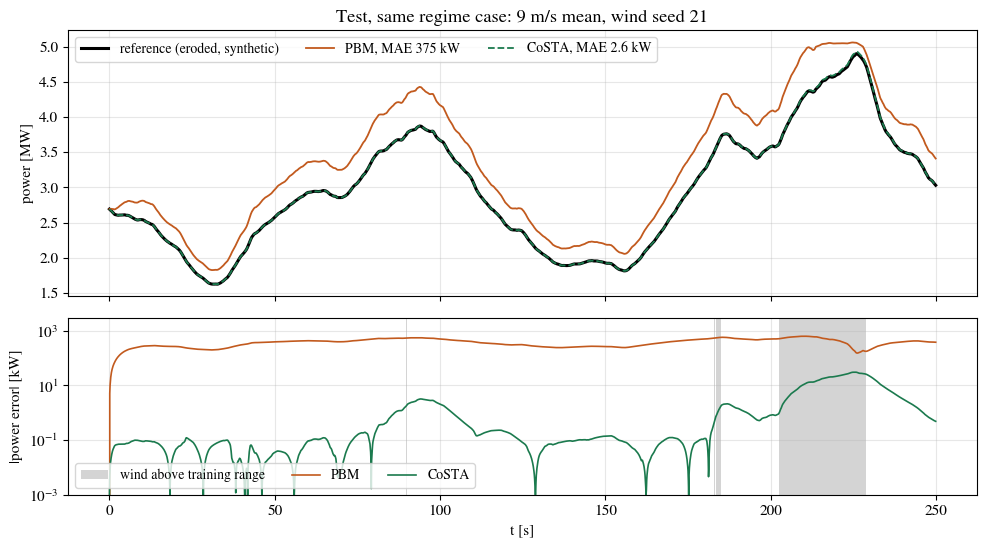

In [9]:
L_show_ref, L_show_nom = REF[SHOW_CASE], NOM[SHOW_CASE]
L_show_cs = simulate(WIND[SHOW_CASE], costa_aero(costa))
row_show = next(rw for rw in rows if (rw['v_mean'], rw['wind_seed']) == SHOW_CASE)
t_ax = np.arange(N_SAMPLES)*DT

def plot_wind_costa_correction():
    fig, ax = plt.subplots(2, 1, figsize=(10, 5.6), sharex=True, gridspec_kw=dict(height_ratios=[1.5, 1]))
    ax[0].plot(t_ax, L_show_ref['P']/1e6, color=fg(), lw=2.2, label='reference (eroded, synthetic)')
    ax[0].plot(t_ax, L_show_nom['P']/1e6, 'C1', lw=1.3,
               label=f"PBM, MAE {row_show['pbm']['power_mae_kw']:.0f} kW")
    ax[0].plot(t_ax, L_show_cs['P']/1e6, 'C2', lw=1.3, ls='--',
               label=f"CoSTA, MAE {row_show['costa']['power_mae_kw']:.1f} kW")
    ax[0].set(ylabel='power [MW]',
              title=f'{ROLE_LABEL[CASE_ROLE[SHOW_CASE]].capitalize()} case: {SHOW_CASE[0]:g} m/s mean, '
                    f'wind seed {SHOW_CASE[1]}')
    ax[0].legend(fontsize=10, loc='upper left', ncol=3)
    above = L_show_ref['v'] > BOX['train'][1][1]
    ax[1].fill_between(t_ax, 1e-3, 1e4, where=above, color=muted(), alpha=0.25, lw=0,
                       label='wind above training range')
    ax[1].semilogy(t_ax, np.abs(L_show_nom['P'] - L_show_ref['P'])/1e3, 'C1', lw=1.2, label='PBM')
    ax[1].semilogy(t_ax, np.maximum(np.abs(L_show_cs['P'] - L_show_ref['P'])/1e3, 1e-3), 'C2', lw=1.2, label='CoSTA')
    ax[1].set(xlabel='t [s]', ylabel='|power error| [kW]', ylim=(1e-3, 3e3))
    ax[1].legend(fontsize=10, loc='lower left', ncol=3)
    plt.tight_layout()

save_dual(plot_wind_costa_correction, 'wind_costa_correction', FIG)
plt.show()

Top: on the held-out 9/21 case the PBM over-predicts power throughout, by 375 kW on average, while CoSTA's trace
lies on the reference. Bottom, on a log scale: CoSTA's error is about 0.1 kW for most of the record and rises to
10–30 kW around $t\approx200$–230 s. That is when the wind exceeds the largest training wind (shaded), so the
rollout visits states the network was never fitted on. The error then decays once the wind returns to the training
range. The same thing happens, on a smaller scale, at the brief excursions near 90 s and 185 s.

## 5. What was learned: the torque deficit, in physical units

Because the data are synthetic, we can compare the learned correction with the oracle deficit $\delta$ that generated
them. The left panel is a parity plot on the states visited by the CoSTA rollouts: training cases in a light colour,
held-out cases in full colour. The right panel converts the correction into a fractional loss of aerodynamic torque,
$-\sigma_{\boldsymbol{\theta}}/T_{\text{aero}}^{\text{nom}}$, and plots it against the tip-speed ratio together with the erosion law.

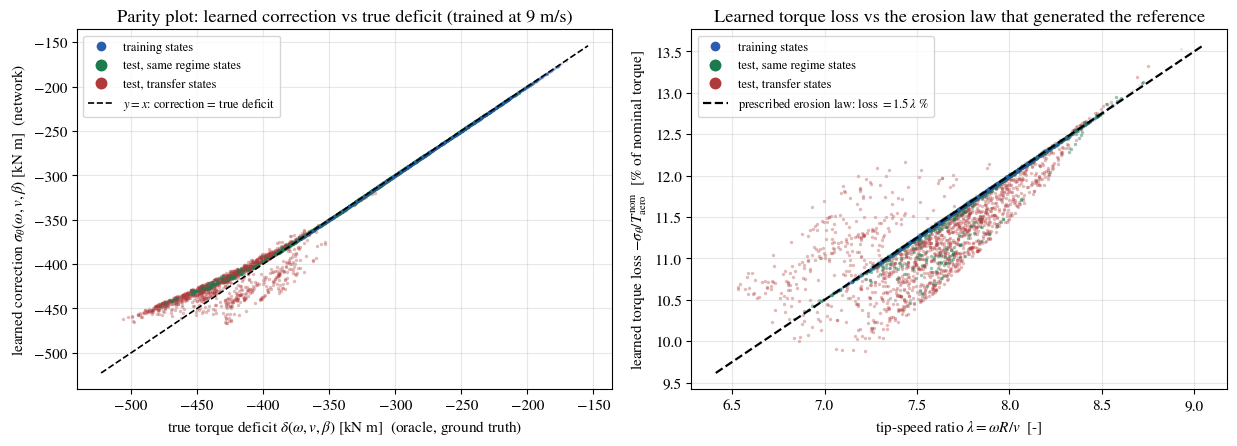

In [10]:
def visited(cases):
    S = []
    for c in cases:
        L = simulate(WIND[c], costa_aero(costa)); S.append(np.column_stack([L['omega'][:-1], L['v'], L['beta']]))
    return np.vstack(S)

VIS = {role: visited(SPLIT[role]) for role in ['train', 'test_same', 'test_transfer']}

def plot_wind_costa_recovery():
    """Left: parity plot of the learned correction against the true (oracle) torque deficit at the same state.
    Right: the learned correction as a percentage of nominal torque against tip-speed ratio, with the erosion law."""
    fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.6))
    role_draw = [('train', 0.15, 4, 3), ('test_same', 0.45, 6, 2), ('test_transfer', 0.35, 6, 1)]
    for role, alpha_pt, sz, z in role_draw:
        S = VIS[role][::3]
        ax[0].scatter(deficit(*S.T)/1e3, costa.batch(S)/1e3, s=sz, alpha=alpha_pt, color=ROLE_COLOR[role],
                      label=ROLE_LABEL[role] + ' states', zorder=z, lw=0)
    lims = np.array(ax[0].get_xlim())
    ax[0].plot(lims, lims, '--', color=fg(), lw=1.2, zorder=4, label='$y=x$: correction = true deficit')
    ax[0].set(xlabel=r'true torque deficit $\delta(\omega,v,\beta)$ [kN m]  (oracle, ground truth)',
              ylabel=r'learned correction $\sigma_\theta(\omega,v,\beta)$ [kN m]  (network)',
              title='Parity plot: learned correction vs true deficit (trained at 9 m/s)')
    leg = ax[0].legend(fontsize=9, markerscale=3.5, loc='upper left')
    for h in leg.legend_handles:
        h.set_alpha(1)
    for role, alpha_pt, sz, z in role_draw:
        S = VIS[role][::3]; lam = S[:, 0]*R_ROT/S[:, 1]
        ax[1].scatter(lam, -100*costa.batch(S)/T_nom(*S.T), s=sz, alpha=alpha_pt, color=ROLE_COLOR[role],
                      label=ROLE_LABEL[role] + ' states', zorder=z, lw=0)
    lg = np.linspace(*ax[1].get_xlim(), 50)
    ax[1].plot(lg, 100*EROSION*lg, '--', color=fg(), lw=1.6, zorder=4,
               label=r'prescribed erosion law: loss $=1.5\,\lambda$ %')
    ax[1].set(xlabel=r'tip-speed ratio $\lambda=\omega R/v$  [-]',
              ylabel=r'learned torque loss $-\sigma_\theta/T^{\mathrm{nom}}_{\mathrm{aero}}$  [% of nominal torque]',
              title='Learned torque loss vs the erosion law that generated the reference')
    leg = ax[1].legend(fontsize=9, markerscale=3.5, loc='upper left')
    for h in leg.legend_handles:
        h.set_alpha(1)
    plt.tight_layout()

save_dual(plot_wind_costa_recovery, 'wind_costa_recovery', FIG)
plt.show()

On the training states the learned correction lies on the parity line, and so do most same-regime test states.
The exceptions are the gust states of case 9/21, which leave the training box and fall among the transfer points.
On the transfer states the correction bends away: for deficits beyond about $-380$ kN·m, which occur only at higher wind, the
learned correction is off by up to about 50 kN·m, in either direction. The right panel shows the same thing as a fraction of
the nominal torque. Inside the training data, which cover only a narrow band of $\lambda$ near $\lambda_{\text{opt}}$
because the controller tracks it, the learned fraction follows the erosion law $1.5\lambda$ %. The transfer states
(and the 9/21 gust states) spread off it, both at low $\lambda$ (strong wind, pitch active) and inside the band, where the pitch is the new input.

The correction is a torque in physical units, and here it agrees with the oracle. That is not proof that an
erosion mechanism has been identified. The agreement is checked against an oracle that a real data set would not
have. The label equals $\delta$ only because the synthetic reference uses the PBM's own integrator. And on a
one-dimensional operating curve, many different mechanisms (erosion, fouling, a wrong $C_p$ map, a wrong air
density) can produce similar torque deficits. Separating them needs data that excite other operating points.

## 6. Scaling the correction

Multiply the correction by $\alpha\in[0,1]$ and rerun the same-regime test case. $\alpha=0$ is the PBM, an identity
asserted above. The intermediate values are an observation about this model and this case, not a guarantee.

In [11]:
alpha_err = [power_mae_kw(simulate(WIND[SHOW_CASE], costa_aero(costa, a)), REF[SHOW_CASE]) for a in ALPHAS]
for a, e in zip(ALPHAS, alpha_err):
    print(f'alpha = {a:4.2f}: power MAE {e:7.1f} kW')

alpha = 0.00: power MAE   374.8 kW
alpha = 0.25: power MAE   288.0 kW
alpha = 0.50: power MAE   197.6 kW
alpha = 0.75: power MAE   101.4 kW
alpha = 1.00: power MAE     2.6 kW


On this case the power MAE falls almost linearly with $\alpha$, from 375 kW at $\alpha=0$ to 2.6 kW at $\alpha=1$.
That is an observation for this model on this case. Because the correction enters the closed loop, a different
model or case need not behave monotonically. The only general statement is the identity: $\alpha=0$ reproduces the
PBM step from the current state, and it does not undo error already accumulated in a rollout.

## 7. Transfer to the pitch-controlled regime: coverage and input ablations

The transfer cases at 11.5 m/s put the turbine around and above rated wind. The pitch is active for about 40 % of the
steps and most states lie outside the training box, so the network is asked for corrections at $(\omega,v,\beta)$
it never saw. Two declared ablations separate the possible causes:

* **coverage**: retrain with the training set augmented by two 12 m/s realizations (seeds 41, 42) that do pitch;
* **pitch input**: the same augmented training set, but the network sees only $(\omega,v)$.

Everything else is unchanged, including the 9 m/s validation set used to select each checkpoint. All models are
then evaluated, frozen, on the same test cases.

In [12]:
VARIANTS = {'9 m/s': (CASES_TRAIN, (0, 1, 2))}
if RUN_COVERAGE_ABLATION:
    VARIANTS['9 + 12 m/s'] = (CASES_TRAIN + CASES_AUG, (0, 1, 2))
    if RUN_PITCH_ABLATION:
        VARIANTS['9 + 12 m/s, no pitch input'] = (CASES_TRAIN + CASES_AUG, (0, 1))
FITTED = {'9 m/s': (costa, info, rows)}
for name, (tc, cols) in VARIANTS.items():
    if name not in FITTED:
        t0 = time.time(); c_v, i_v = fit_costa(tc, cols=cols); FITTED[name] = (c_v, i_v, evaluate(c_v))
        print(f"{name:28s}: selected step {i_v['best_step']}, validation power MAE "
              f"{i_v['best_val_power_mae']:.2f} kW, {time.time()-t0:.0f} s")

TEST_CASES = [c for role in ['test_same', 'test_transfer', 'historical'] for c in SPLIT[role]]

def case_key(c):
    return f'{c[0]:g}/{c[1]}'

def get(rws, c, model, m='power_mae_kw'):
    return next(rw[model][m] for rw in rws if (rw['v_mean'], rw['wind_seed']) == c)

for m, unit in [('power_mae_kw', 'power MAE [kW]'), ('torque_err_knm', 'torque-correction error [kN m]')]:
    print(f'\n{unit}, seed {SEED}')
    print(f"{'case':30s} {'PBM':>8s}" + ''.join(f'{n:>28s}' for n in VARIANTS))
    for c in TEST_CASES:
        print(f"{ROLE_LABEL[CASE_ROLE[c]] + ' ' + case_key(c):30s} {get(rows, c, 'pbm', m):8.1f}"
              + ''.join(f"{get(FITTED[n][2], c, 'costa', m):28.2f}" for n in VARIANTS))
print('failed rollouts:', sum(rw['costa']['failed'] for n in VARIANTS for rw in FITTED[n][2]))

9 + 12 m/s                  : selected step 3000, validation power MAE 0.08 kW, 13 s


9 + 12 m/s, no pitch input  : selected step 2500, validation power MAE 0.23 kW, 14 s

power MAE [kW], seed 0
case                                PBM                       9 m/s                  9 + 12 m/s  9 + 12 m/s, no pitch input
test, same regime 9/21            374.8                        2.63                        0.14                        1.14
test, same regime 9/22            334.0                        0.08                        0.12                        0.29
test, transfer 11.5/31            316.5                       11.11                        0.46                        9.95
test, transfer 11.5/32            307.1                        9.25                        0.30                        8.70
historical diagnostic 11.5/5      178.5                       11.54                        0.46                        8.07

torque-correction error [kN m], seed 0
case                                PBM                       9 m/s                  9 + 12 m/s  9 + 12 m/s

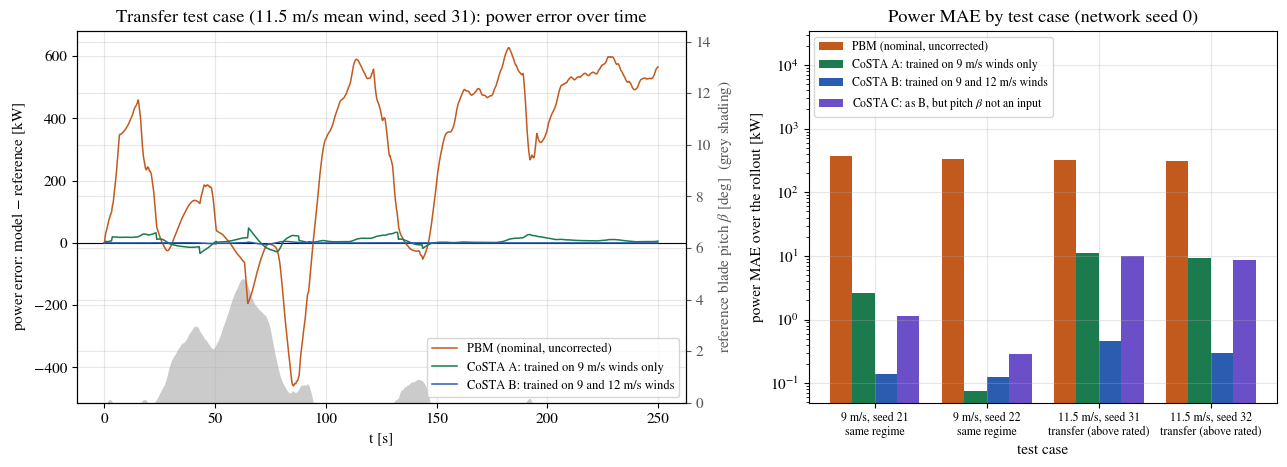

In [13]:
L_tr_ref, L_tr_nom = REF[SHOW_TRANSFER], NOM[SHOW_TRANSFER]
L_tr = {n: simulate(WIND[SHOW_TRANSFER], costa_aero(FITTED[n][0])) for n in VARIANTS if 'no pitch' not in n}
VAR_STYLE = {'9 m/s': ('C2', 'CoSTA A: trained on 9 m/s winds only'),
             '9 + 12 m/s': ('C0', 'CoSTA B: trained on 9 and 12 m/s winds'),
             '9 + 12 m/s, no pitch input': ('C4', r'CoSTA C: as B, but pitch $\beta$ not an input')}
PLOT_CASES = [c for role in ['test_same', 'test_transfer'] for c in SPLIT[role]]   # the historical case is a diagnostic only

def plot_wind_costa_general():
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw=dict(width_ratios=[1.3, 1]))
    ax2 = ax[0].twinx()
    ax2.fill_between(t_ax, 0, L_tr_ref['beta'], color=muted(), alpha=0.3, lw=0)
    ax2.set_ylim(0, 3*max(L_tr_ref['beta'].max(), 1))
    ax2.set_ylabel(r'reference blade pitch $\beta$ [deg]  (grey shading)', color=muted()); ax2.tick_params(axis='y', colors=muted())
    ax[0].set_zorder(ax2.get_zorder() + 1); ax[0].patch.set_visible(False)
    ax[0].axhline(0, color=fg(), lw=0.8)
    ax[0].plot(t_ax, (L_tr_nom['P'] - L_tr_ref['P'])/1e3, 'C1', lw=1.1, label='PBM (nominal, uncorrected)')
    for n, L in L_tr.items():
        ax[0].plot(t_ax, (L['P'] - L_tr_ref['P'])/1e3, color=VAR_STYLE[n][0], lw=1.1, label=VAR_STYLE[n][1])
    ax[0].set(xlabel='t [s]', ylabel='power error: model $-$ reference [kW]',
              title=f'Transfer test case ({SHOW_TRANSFER[0]:g} m/s mean wind, seed {SHOW_TRANSFER[1]}): power error over time')
    ax[0].legend(fontsize=9, loc='lower right')
    xs = np.arange(len(PLOT_CASES)); names = ['PBM', *VARIANTS]; w = 0.8/len(names)
    for j, n in enumerate(names):
        vals = [get(rows, c, 'pbm') if n == 'PBM' else get(FITTED[n][2], c, 'costa') for c in PLOT_CASES]
        col, lab = ('C1', 'PBM (nominal, uncorrected)') if n == 'PBM' else VAR_STYLE[n]
        ax[1].bar(xs + (j - (len(names) - 1)/2)*w, vals, w, color=col, label=lab)
    ax[1].set_yscale('log')
    ax[1].set_xticks(xs, [f'{c[0]:g} m/s, seed {c[1]}\n' + ('same regime' if CASE_ROLE[c] == 'test_same' else 'transfer (above rated)')
                          for c in PLOT_CASES], fontsize=8.5)
    ax[1].set(xlabel='test case', ylabel='power MAE over the rollout [kW]',
              title=f'Power MAE by test case (network seed {SEED})')
    ax[1].legend(fontsize=8.5, loc='upper left', ncol=1)
    ax[1].set_ylim(top=ax[1].get_ylim()[1]*60)
    plt.tight_layout()

save_dual(plot_wind_costa_general, 'wind_costa_general', FIG)
plt.show()

Left: on transfer case 11.5/31 the PBM's error is large and changes sign during the pitch events (shaded), because
its own controller pitches at different times from the reference. The model trained at 9 m/s removes most of that
error but leaves a residual of up to about 50 kW, both during pitch events and in the first 20 s, when the rotor
runs faster than in any training state. The model trained with the extra 12 m/s realizations stays close to zero.

Right, all test cases with seed 0:

* **Coverage.** With the same network and inputs, adding the two 12 m/s realizations cuts the transfer power MAE
  from 9–11 kW to 0.3–0.5 kW, and the torque-correction error from about 16 kN·m to about 1 kN·m. It also fixes the
  gust in the same-regime case 9/21 (2.6 kW to 0.14 kW).
* **Inputs.** Coverage alone is not enough. With the same augmented training set but without the pitch input, the
  transfer error stays at 9–10 kW, close to the 9 m/s model: without $\beta$ the network cannot tell pitched
  states from unpitched ones at similar $(\omega,v)$. Its validation MAE (0.23 kW against 0.08 kW) would already
  have ruled it out, without looking at the test cases.

So in this experiment transfer to the pitch-controlled regime was decided by what the training data covered and by
whether the network could see the variable that distinguishes the regimes, not by the CoSTA formulation itself.
Section 8 checks that the ordering holds across initialization seeds.

## 8. Seeds

One training run is one draw. We retrain every model variant for the declared initialization seeds under the same
protocol and report the median and range across seeds of each test metric. Nothing here is used to choose a model.

In [14]:
def spread(vals):
    v = np.array(vals, float)
    return dict(median=float(np.median(v)), min=float(v.min()), max=float(v.max()),
                n_nonfinite=int((~np.isfinite(v)).sum()))

def summarize(rws):
    return {case_key((rw['v_mean'], rw['wind_seed'])): rw['costa'] for rw in rws}

if RUN_SEED_SWEEP:
    t0 = time.time(); sweep = {}
    for name, (tc, cols) in VARIANTS.items():
        for s in SWEEP_SEEDS:
            if s == SEED:
                c_s, i_s, r_s = FITTED[name]                       # reuse the models trained above
            else:
                c_s, i_s = fit_costa(tc, seed=s, cols=cols)
                r_s = evaluate(c_s, roles=('test_same', 'test_transfer', 'historical'))
            sweep[(name, s)] = dict(best_step=i_s['best_step'], val=i_s['best_val_power_mae'], test=summarize(r_s))
    seed_table = {}
    for name in VARIANTS:
        tab = {'validation power_mae_kw': spread([sweep[(name, s)]['val'] for s in SWEEP_SEEDS])}
        for c in TEST_CASES:
            for m in ['power_mae_kw', 'speed_rmse_rpm', 'torque_err_knm']:
                tab[f'{case_key(c)} {m}'] = spread([sweep[(name, s)]['test'][case_key(c)][m] for s in SWEEP_SEEDS])
        tab['failed rollouts'] = sum(sweep[(name, s)]['test'][case_key(c)]['failed']
                                     for s in SWEEP_SEEDS for c in TEST_CASES)
        tab['selected steps'] = [sweep[(name, s)]['best_step'] for s in SWEEP_SEEDS]
        seed_table[name] = tab
    print(f'seed sweep: {time.time()-t0:.0f} s')
else:
    with open(RESULTS_FILE) as fh:
        seed_table = json.load(fh)['seed_sweep']
    print('seed sweep not rerun: table loaded from', os.path.relpath(RESULTS_FILE))

print(f"power MAE [kW] over seeds {SWEEP_SEEDS}: median [min, max]")
print(f"{'case':30s}" + ''.join(f'{n:>30s}' for n in seed_table))
for key in ['validation'] + [case_key(c) for c in TEST_CASES]:
    lab = 'validation (mean of 2)' if key == 'validation' else ROLE_LABEL[CASE_ROLE[next(c for c in TEST_CASES
                                                                                       if case_key(c) == key)]] + ' ' + key
    cells = [seed_table[n][f'{key} power_mae_kw'] for n in seed_table]
    print(f'{lab:30s}' + ''.join(f"{d['median']:10.2f} [{d['min']:6.2f}, {d['max']:6.2f}]" for d in cells))
for n, tab in seed_table.items():
    print(f"{n:28s} failed rollouts: {tab['failed rollouts']}, selected steps: {tab['selected steps']}")

seed sweep: 110 s
power MAE [kW] over seeds [0, 1, 2, 3, 4]: median [min, max]
case                                                   9 m/s                    9 + 12 m/s    9 + 12 m/s, no pitch input
validation (mean of 2)              0.07 [  0.04,   0.07]      0.08 [  0.03,   0.58]      0.19 [  0.16,   0.24]
test, same regime 9/21              2.46 [  1.87,   2.89]      0.15 [  0.12,   0.76]      1.20 [  1.08,   1.43]
test, same regime 9/22              0.07 [  0.05,   0.10]      0.12 [  0.05,   0.52]      0.24 [  0.18,   0.34]
test, transfer 11.5/31             12.54 [ 11.11,  13.23]      0.71 [  0.46,   1.03]     10.46 [  9.95,  10.78]
test, transfer 11.5/32              9.65 [  8.77,  12.45]      0.42 [  0.30,   0.72]      8.99 [  8.70,   9.15]
historical diagnostic 11.5/5       11.54 [  8.97,  14.11]      0.60 [  0.46,   0.90]      8.82 [  8.07,   8.88]
9 m/s                        failed rollouts: 0, selected steps: [3000, 3000, 3000, 3000, 3000]
9 + 12 m/s                   fai

Across the five seeds no rollout fails. On the transfer and historical cases the ordering seen with seed 0 holds for
every seed; the ranges do not overlap:

* model trained at 9 m/s only: median transfer power MAE 12.5 and 9.7 kW (range 8.8–13.2 kW), 9/21 2.5 kW,
  9/22 0.07 kW;
* with the 12 m/s realizations: median transfer power MAE 0.71 and 0.42 kW (range 0.30–1.03 kW), and below 0.8 kW on
  every same-regime case and seed;
* same augmented data without the pitch input: median transfer power MAE 10.5 and 9.0 kW.

On the in-box case 9/22 all three models are within 0.05–0.52 kW, and the 9 m/s model is slightly better in
median, so there the differences are within seed variation. One augmented seed also has a worse validation MAE
(0.58 kW). The seed-to-seed range is small compared with the gaps between models on the transfer cases. All with-pitch models were selected at the
final step, so a larger step budget might lower all their errors somewhat; the comparison between models is made at
the same budget. Read any single-run number in this notebook with the seed ranges in mind.

In [15]:
results = dict(
    provenance='synthetic: simulated NREL-5MW-like turbine with a prescribed erosion law; no measured data',
    config={k: globals()[k] for k in DEFAULTS} | dict(RUN_COVERAGE_ABLATION=RUN_COVERAGE_ABLATION,
                                                       RUN_PITCH_ABLATION=RUN_PITCH_ABLATION,
                                                       SWEEP_SEEDS=SWEEP_SEEDS, CASES_HISTORICAL=CASES_HISTORICAL,
                                                       NOISE_SEED=NOISE_SEED, label_route='residual from logs',
                                                       metrics_units=dict(power_mae='kW', speed_rmse='rpm',
                                                                          torque_err='kN m')),
    manifest=MANIFEST,
    regimes={case_key(c): dict(role=CASE_ROLE[c], **g) for c, g in REGIME.items()},
    selected={n: dict(train_cases=VARIANTS[n][0], inputs=['omega', 'v', 'beta'][:len(VARIANTS[n][1])],
                      best_step=FITTED[n][1]['best_step'], stopped_at=FITTED[n][1]['stopped_at'],
                      best_val_power_mae_kw=FITTED[n][1]['best_val_power_mae'], normalization=FITTED[n][1]['stats'])
              for n in VARIANTS},
    metrics={n: FITTED[n][2] for n in VARIANTS},
    alpha_check=dict(case=case_key(SHOW_CASE), alphas=ALPHAS, power_mae_kw=alpha_err),
    seed_sweep=seed_table)
with open(RESULTS_FILE, 'w') as fh:
    json.dump(results, fh, indent=1)
print('saved', os.path.relpath(RESULTS_FILE), f'; total runtime {time.time()-T_START:.0f} s')

if AT_DEFAULTS:
    same = [rw for rw in rows if rw['role'] == 'test_same']
    assert all(not rw['costa']['failed'] and rw['costa']['power_mae_kw'] < 0.1*rw['pbm']['power_mae_kw'] for rw in same)
else:
    print('regression check skipped (non-default parameters)')

saved ../data/costa_turbine_results.json ; total runtime 150 s


**Summary.**

* The data are synthetic: a simulated turbine with a prescribed erosion law. That lets us check every label and
  every prediction against the truth; it is not evidence about real turbines.
* Labels come from synchronized logs, $\sigma^*_k=J(\omega_{k+1}-\omega_k)/\Delta t+T_{\text{gen},k}-T^{\text{nom}}_{\text{aero},k}$,
  with every quantity at the same step. With clean logs and the PBM's own integrator the label equals the true
  torque deficit; with noise or a different integrator it would not.
* Training fits $\sigma_{\boldsymbol{\theta}}(\omega,v,\beta)$ on three 9 m/s realizations, validation rollouts select the
  checkpoint, and the frozen model is tested by recursive closed-loop simulation on held-out wind.
* In the training regime the power error drops from 330–375 kW (PBM) to 0.08–2.6 kW. The worst same-regime case is the
  one whose wind leaves the training range.
* At 11.5 m/s, where the pitch controller is active, the 9 m/s model leaves about 10 kW. Adding pitched training
  data reduces this to below 1 kW, but only when the network also sees the pitch.
* $\alpha=0$ reproduces the PBM exactly. That is an identity, not a guarantee about the corrected model.

The correction is a smooth function of the state in physical units. Module 21 (equation discovery) asks the next
question: can a sparse symbolic regression turn such a correction into a compact formula such as $-0.015\,\lambda\,T^{\text{nom}}_{\text{aero}}$,
and what data would be needed to tell that formula apart from other candidates?